# Q2: Weather Classification Using a Decision Tree

**Subject:** Machine Learning Lab  
**Topic:** Decision Tree Classifier

## Aim
To build a Decision Tree Classification model that predicts whether to play based on weather conditions.

Weather Dataset:


,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


Training Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00         5
         Yes       1.00      1.00      1.00         9

    accuracy                           1.00        14
   macro avg       1.00      1.00      1.00        14
weighted avg       1.00      1.00      1.00        14



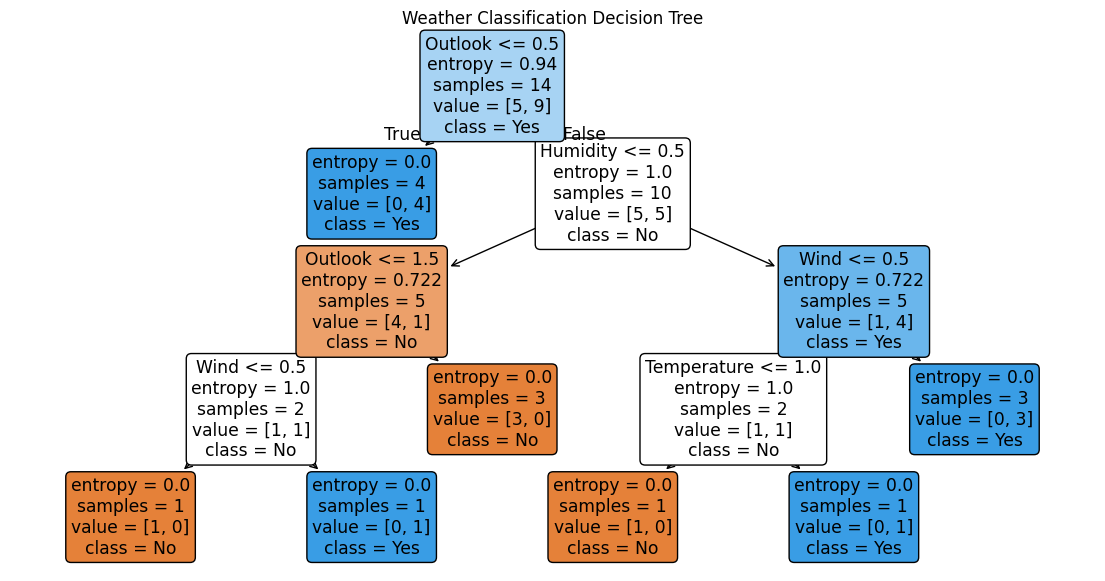

In [1]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

# Create a sample weather dataset
data = {
    "Outlook": ["Sunny", "Sunny", "Overcast", "Rain", "Rain",
                "Rain", "Overcast", "Sunny", "Sunny", "Rain",
                "Sunny", "Overcast", "Overcast", "Rain"],
    "Temperature": ["Hot", "Hot", "Hot", "Mild", "Cool",
                    "Cool", "Cool", "Mild", "Cool", "Mild",
                    "Mild", "Mild", "Hot", "Mild"],
    "Humidity": ["High", "High", "High", "High", "Normal",
                 "Normal", "Normal", "High", "Normal", "Normal",
                 "Normal", "High", "Normal", "High"],
    "Wind": ["Weak", "Strong", "Weak", "Weak", "Weak",
             "Strong", "Strong", "Weak", "Weak", "Weak",
             "Strong", "Strong", "Weak", "Strong"],
    "Play": ["No", "No", "Yes", "Yes", "Yes", "No", "Yes",
             "No", "Yes", "Yes", "Yes", "Yes", "Yes", "No"]
}

df = pd.DataFrame(data)
print("Weather Dataset:")
display(df)

# Encode categorical columns
encoders = {}
encoded_df = df.copy()

for column in df.columns:
    encoders[column] = LabelEncoder()
    encoded_df[column] = encoders[column].fit_transform(df[column])

X = encoded_df.drop("Play", axis=1)
y = encoded_df["Play"]

# Train the decision tree
model = DecisionTreeClassifier(criterion="entropy", random_state=42)
model.fit(X, y)

# Evaluate on the same dataset (training performance)
predictions = model.predict(X)
print("Training Accuracy:", round(accuracy_score(y, predictions) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y, predictions, target_names=encoders["Play"].classes_))

# Visualize the tree
plt.figure(figsize=(14, 7))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=encoders["Play"].classes_,
    filled=True,
    rounded=True
)
plt.title("Weather Classification Decision Tree")
plt.show()

## Result

The Decision Tree Classification algorithm was implemented successfully using a sample weather dataset. The model used Outlook, Temperature, Humidity, and Wind to predict whether to play.

- **Dataset size:** 14 records
- **Model:** Decision Tree Classifier using entropy
- **Training accuracy:** 100%
- **Evaluation:** Classification report
- **Visualization:** Decision tree plotted successfully

## Conclusion

The experiment demonstrated how a Decision Tree Classifier can learn rules from weather conditions to predict whether to play. The model classified all 14 training records correctly. Further evaluation on unseen data is required to assess its generalization performance.